int L  0.00025427678581320693
err L  1.1440756686274063e-05
int R  0.00025624553564427844
err R  9.920471578300667e-06


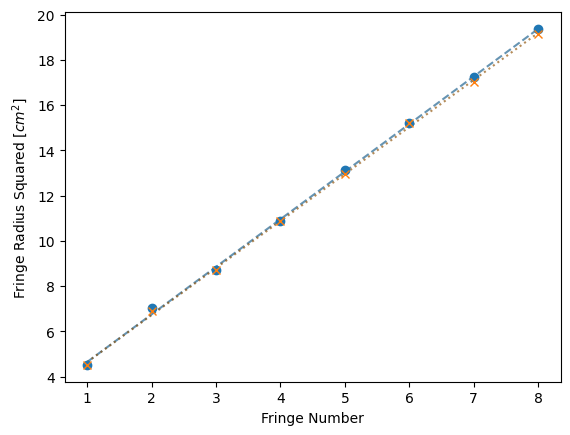

In [29]:
import numpy as np
import math 
import matplotlib.pyplot as plt
from matplotlib import rcParams
import pandas as pd
import scipy.optimize as scpo


row_start_end = [3,9] 
col_start_end = "R:T"   
file_name = "UDS_NewtonsRings"  

pd_file = pd.read_excel(file_name + ".xlsx")
#just_data = pd_file.iloc[row_start_end[0]-2:row_start_end[1]-1]
#val_lst = np.array(just_data.values.tolist())

fring_number = np.array(pd_file["(m-1) number of fringe"][28:36].values.tolist())
fring_radius2_L = np.array(pd_file["(P_m)^2 L"][28:36].values.tolist())
fring_radius2_R= np.array(pd_file["(P_m)^2 R"][28:36].values.tolist())
err_fring_radius2_L = np.array(pd_file["Err on (P_m)^2 L"][28:36].values.tolist())
err_fring_radius2_R= np.array(pd_file["Err on (P_m)^2 R"][28:36].values.tolist())

cm_fring_rad_L = fring_radius2_L * 10000
err_cm_fring_rad_L = err_fring_radius2_L * 10000 


#Best Fit Liine Code
def Line(x, gradient, intercept): 
    return gradient*x + intercept
#Lucas 
actual_fit_parameters_L, covariance_matrix_L = scpo.curve_fit(Line, fring_number,fring_radius2_L)
gradient_L = actual_fit_parameters_L[0]
intercept_L = actual_fit_parameters_L[1]
grad_err_L= np.sqrt(covariance_matrix_L[0,0])
intercept_err_L = np.sqrt(covariance_matrix_L[1,1])
bfl_L = Line(fring_number,gradient_L,intercept_L)

#Ruben
actual_fit_parameters_R, covariance_matrix_R = scpo.curve_fit(Line, fring_number,fring_radius2_R)
gradient_R = actual_fit_parameters_R[0]
intercept_R = actual_fit_parameters_R[1]
grad_err_R= np.sqrt(covariance_matrix_R[0,0])
intercept_err_R = np.sqrt(covariance_matrix_R[1,1])
bfl_R = Line(fring_number,gradient_R,intercept_R)
print("int L ", intercept_L)
print("err L ", intercept_err_L)
print("int R ", intercept_R)
print("err R ", intercept_err_R)
#Residuals 

resid_L = fring_radius2_L-(fring_number*gradient_L + intercept_L)
resid_R = fring_radius2_R-(fring_number*gradient_R + intercept_R)

#Plots

fig = plt.figure(1)

t2_Lplot = plt.errorbar(fring_number, fring_radius2_L*10000, yerr = err_fring_radius2_L , fmt = 'o')
t2_Rplot = plt.errorbar(fring_number, fring_radius2_R*10000, yerr = err_fring_radius2_R , fmt = 'x')
best_fit_line_plotL = plt.plot(fring_number,bfl_L*10000, color = (0,0.3,0.5,0.6), ls = '--')
best_fit_line_plotR = plt.plot(fring_number,bfl_R*10000, color = (0.55,0.3,0,0.65), ls = ':')


plt.ylabel(r"Fringe Radius Squared $[cm^2]$")

#fig.add_axes((0.13,-0.5,0.75,0.25))
#resid_L = plt.scatter(fring_number,resid_L)
#plt.ylabel(r"Residuals")

plt.xlabel(r'Fringe Number')
plt.show()


In [ ]:
fring_number = np.array(pd_file["(m-1) number of fringe"][28:36].values.tolist())
fring_radius2_L = np.array(pd_file["(P_m)^2 L"][28:36].values.tolist())
fring_radius2_R= np.array(pd_file["(P_m)^2 R"][28:36].values.tolist())
err_fring_radius2_L = np.array(pd_file["Err on (P_m)^2 L"][28:36].values.tolist())
err_fring_radius2_R= np.array(pd_file["Err on (P_m)^2 R"][28:36].values.tolist())